Code to create the ZERs timeline chart, including bars for supply and demand uncertainty

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from matplotlib import rcParams
#import matplotlib.patches as mpatches


Run the ZERs model to find the central estimate for accumulated demand

In [4]:
# ZERs model

def run_ZERs(file, TechShare_col_name, Demand_col_name):
    """
    Runs the ZERs model to compute key resource and emissions outputs based on input process coefficients,
    technology shares, and system demands from an Excel file.

    Parameters
    ----------
    file : str
        Path to the Excel file containing model data, including process coefficients, technology shares, and demands.
    TechShare_col_name : str
        Name of the column in the TechShares sheet representing the technology share scenario to use.
    Demand_col_name : str
        Name of the column in the Demand sheet representing the demand scenario to use.

    Returns
    -------
    dict
        A dictionary with the following keys:
        - 'Bio': float, biomass capacity consumption (negative sign indicates use)
        - 'CS': float, carbon storage amount
        - 'NEE': float, net electricity consumption (negative sign indicates use)
        - 'NetEmissions': float, net emissions value, calculated differently depending on NETs mode

    Raises
    ------
    SystemExit
        If input validation fails due to empty activities or circularity issues, the function will print
        an error message and exit the program.
    """  
    from FunExtractInputs import ZERS_LoadInputs
    from FunCheckInputs import ZERs_CheckInputs
    from FunFindRates import ZERs_FindRates
    import sys
    
    
    # The results are returned in a dictionary - initialise that here
    Results={}
    
    # Read the model coefficients and model inputs into dataframes
    (Process_Coeffs, q_System, Process_Shares) = ZERS_LoadInputs(file, TechShare_col_name, Demand_col_name)
    
    # Scale the recipes to get scaled P
    Production_Matrix = Process_Coeffs.mul(Process_Shares.values, axis=0).groupby(level=0).sum().T
    
    np.savetxt("../Output/CSVs/matP.csv", Production_Matrix.values, delimiter=',')
    
    # Check that the model can be solved and that process shares sum to zero
    (NETsMode, CicularityWarning, WarningEmptyActivity, IncompleteProcesses) = ZERs_CheckInputs(Production_Matrix, q_System, Process_Shares)
    
    if WarningEmptyActivity !=0:
        print('Empty activity warning! Calculation ended without solving. A (non-NETs) activity has no processes assigned.')
        sys.exit()
    
    if CicularityWarning:
        print('Circularity warning! Calculation ended without solving.')
        sys.exit()
    
    if len(IncompleteProcesses) != 0:
        print("Warning: Technology shares do not add to 100% for all activities! Check process shares for: ", IncompleteProcesses)
    
    # Find the process rates needed to satisfy the model inputs
    Solution = {}
    Solution = ZERs_FindRates(Production_Matrix, q_System, Process_Shares, NETsMode)
    
    s = Solution['s']
    
    # Select the resources which are external  
    if NETsMode == 0:
        selected_resources = ["BiomassCapacity", "CO2Storage", "NEElectricity", 'NetEmissions']
        P_Ext = Production_Matrix.loc[selected_resources].sort_index(axis = 1).drop('NetEmissions', axis = 1)
        P_System = Production_Matrix.drop(selected_resources, axis = 0).drop('NetEmissions', axis = 1)
        q_System = q_System.drop('NetEmissions', axis = 0)
    else:
        selected_resources = ["BiomassCapacity", "CO2Storage", "NEElectricity"]
        # Split the production matrix into the internal and external resources to create the stacked matrices of P_System and P_Ext
        P_System = Production_Matrix.drop(selected_resources, axis = 0).sort_index(axis = 1).sort_index(axis = 0)
        # np.savetxt("../Output/CSVs/matA.csv", P_System.values, delimiter=',')
        P_Ext = Production_Matrix.loc[selected_resources].sort_index(axis = 1)
        # np.savetxt("../Output/CSVs/matB.csv", P_Ext.values, delimiter=',')
    
    q_model = np.matmul( P_System, np.asarray(s))
    
    u_ZER = np.matmul( P_Ext, np.asarray(s))
    
    
    # Assign each of the elements of the output
    
    Results['Bio'] = u_ZER.loc['BiomassCapacity'].iloc[0]*-1
    Results['CS']= u_ZER.loc['CO2Storage'].iloc[0]
    Results['NEE'] = u_ZER.loc['NEElectricity'].iloc[0]*-1
    if NETsMode== 1:
        Results['NetEmissions'] = q_model.loc['NetEmissions', 0]    
    else: 
        Results['NetEmissions'] = u_ZER.loc['NetEmissions'].iloc[0]
        
    return Results 

In [5]:
### find results for accumulated demands

file = "../Data/Recipe_Coefficients.xls"

runtype = 'Accumulated'
TechShare_sheetn = "TechShares"
Demand_sheetn = "Demand"
TechShare_col_name = 'TechShare2050'
Demand_col_name = '2050 Process Rate'

ZERs_Demand_2050 = run_ZERs(file, TechShare_col_name, Demand_col_name)

NEE_Model = ZERs_Demand_2050["NEE"]
CS_Model = ZERs_Demand_2050["CS"]
Bio_Model = ZERs_Demand_2050["Bio"]

RawFood    1.0
Name: DiagonalEntry, dtype: float64
Matrix inverse solution minimum process rate is  0.12 



Import data for the Monte Carlo runs (the uncertainty in demand)

In [7]:
# import data for all relevant runs
MCResults_Spreadsheet = "../Output/MonteCarlo/monte_carlo_results_Accumulated_10.csv"
MonteCarloRuns_df = pd.read_csv(MCResults_Spreadsheet)
# Find the max and min for each variable 
Demand_Upper = MonteCarloRuns_df.loc[:, ['NEE', 'Bio', 'CS']].max(axis = 0)
Demand_Lower = MonteCarloRuns_df.loc[:, ['NEE', 'Bio', 'CS']].min(axis = 0)

############################ Set up chart for plotting #######################################

In [8]:
####################################### INPUTS/ CHOICES FOR THE PLOTS ######################

Today = 2021
EndYr = 2050
StartYr = 1970


sns.set_context("paper", font_scale = 1, rc={"grid.linewidth": 1})
sns.set(rc={"xtick.bottom" : True, "ytick.left" : True})

palette_elec = ['#c51b7d','#e9a3c9','#e6f5d0','#a1d76a','#4d9221']
palette_bio = ['#a6611a','#dfc27d','#80cdc1','#018571']
palette_cs = ['#762a83','#7fbf7b']

palette_elec = ['#543005', '#bf812d', '#f6e8c3', '#80cdc1' ,'#01665e']
palette_bio = ['#8c510a', '#dfc27d', '#c7eae5', '#35978f']
palette_cs = ['#bf812d', '#bf812d']
# palette_cs = ['#bf812d', '#003c30']
palette_solarwind = ['#f6e8c3', '#80cdc1']

supply_colour = '#003c30'
supply_alpha = 0.7

demand_colour = 'darkred'
demand_alpha = 0.7

############################# IMPORT TRAJECTORY DATA ####################################

In [10]:
sht_name = "ElecGen_Traj_Revised"


Electricity_Generation = pd.read_excel('../Data/GrowthRates/TimelineElectricity.xls', 
                                        sht_name , 
                                        index_col=('Year'))
Electricity_Generation.fillna(0, inplace=True)


Biomass_extraction = pd.read_excel('../Data/GrowthRates/Timeline_Biomass.xls', 
                                        'Biomass_Zhou2018_Linear', 
                                        index_col=('Year'),
                                        usecols=['Year', 'Wood materials', 'Biomass as fuel', 'Crops for food', 'Biomass for livestock'],
                                        nrows = 10)
Biomass_extraction.fillna(0, inplace=True)

In [13]:
# Plot curve from Haszeldine et al. (2018): y = 7E-75 e^(0.0865x)
Years= (EndYr-StartYr)+1

HaszeldineCurveCapacity = np.transpose(pd.DataFrame([np.linspace(StartYr, EndYr, Years), np.zeros(Years)], index=['Year', 'HCurve']))
HaszeldineCurveCapacity['HCurve'] = 7e-75*np.exp(0.0865*HaszeldineCurveCapacity['Year'])/1000

# Scale down capacity to show actual stored CO2
CCS_CapacityFactor = 0.7
HaszeldineCurve = HaszeldineCurveCapacity.copy(deep = True)
HaszeldineCurve.loc[:, 'HCurve'] = HaszeldineCurveCapacity.loc[:, 'HCurve']*CCS_CapacityFactor

# CCS data read project data from excel file
CarbonCaptureCapacity = pd.read_excel('../Data/GrowthRates/TimelineCarbonCapture.xls', 
                                        'CCS_Inst RAW' , 
                                        # 'CCS_Inst',
                                        header = 5)

# replace all non-numeric operational dates with a value
CarbonCaptureCapacity['OPERATIONAL DATE'].replace({"2020's": 2023,'2020s': 2027, '2025 - 2026':2025, 'Mid 2020s':2024, 'N/A':2050, 'Under Evaluation': 2040, '2026-2027':2027}, inplace = True)
CarbonCaptureCapacity['OPERATIONAL DATE'].fillna(2050, inplace= True)

# assign the average facility value to all those which are 'Under Evaluation'. All blank cells are set to zero. These correspond to pipelines etc
AvProjectSize = np.mean(CarbonCaptureCapacity['CAPTURE CAPACITY Mtpa CO2'].loc[CarbonCaptureCapacity['CAPTURE CAPACITY Mtpa CO2']!='Under Evaluation'].dropna(inplace = False))
# CarbonCaptureCapacity['CAPTURE CAPACITY Mtpa CO2'].replace({'Under Evaluation':AvProjectSize}, inplace= True)
CarbonCaptureCapacity['CAPTURE CAPACITY Mtpa CO2'].replace({'Under Evaluation':0}, inplace= True)
CarbonCaptureCapacity.fillna(0, inplace=True)



# Sort projects by date they come online and reset the index
CarbonCaptureCapacity.sort_values(by = ['OPERATIONAL DATE'], inplace=True)
CarbonCaptureCapacity.reset_index(drop=True, inplace=True)

# select operational projects 
CarbonCapture_Operational = CarbonCaptureCapacity[CarbonCaptureCapacity['FACILITY STATUS']=='Operational'].drop(columns = ['FACILITY', 'COUNTRY',	'FACILITY INDUSTRY', 'FACILITY STATUS'])

# sort operational projects into those which are for EOR and those of actual storage. Find the cumulative capacity at each operational date
CarbonCapture_Op_EOR = CarbonCapture_Operational[CarbonCapture_Operational['FACILITY STORAGE CODE']=='Enhanced Oil Recovery'].groupby(['OPERATIONAL DATE']).sum()
CarbonCapture_Op_CS = CarbonCapture_Operational[CarbonCapture_Operational['FACILITY STORAGE CODE']=='Dedicated Geological Storage'].groupby(['OPERATIONAL DATE']).sum()

CarbonCapture_Op_EOR.reset_index()
CarbonCapture_Op_EOR.rename(columns={'CAPTURE CAPACITY Mtpa CO2':'Added EOR Capacity' }, inplace = True)
CarbonCapture_Op_CS.reset_index()
CarbonCapture_Op_CS.rename(columns={'CAPTURE CAPACITY Mtpa CO2':'Added CCS Capacity' }, inplace = True)


CarbonCapture_Cumulative = CarbonCapture_Op_EOR.merge(CarbonCapture_Op_CS, how = 'outer', on = 'OPERATIONAL DATE')
CarbonCapture_Cumulative.fillna(0, inplace=True)
CarbonCapture_Cumulative.sort_index(inplace = True)
CarbonCapture_Cumulative['Cumulative CCS Capacity'] = CarbonCapture_Cumulative['Added CCS Capacity'].cumsum()
CarbonCapture_Cumulative['Cumulative EOR Capacity'] = CarbonCapture_Cumulative['Added EOR Capacity'].cumsum()

CarbonCapture_Cumulative.to_csv("../Output/CCSHitoricalDataSummarised.csv")

CarbonCapture_Cumulative.loc[2050, 'Cumulative CCS Capacity'] = CarbonCapture_Cumulative.loc[2021, 'Cumulative CCS Capacity']
CarbonCapture_Cumulative.loc[2050, 'Cumulative EOR Capacity'] = CarbonCapture_Cumulative.loc[2021, 'Cumulative EOR Capacity']

Lower risk and maximum possible estimates

In [14]:
ZER_Lower = {'NEE':70, 'Bio':12.75, 'CS': 0.1}
ZER_Upper = {'NEE':249, 'Bio':18.2, 'CS': 3.7}

Plot the graph

In [15]:
Demand_Upper['CS']

17.136554033360916

In [16]:
# Font settings

SMALL_SIZE = 12
MEDIUM_SIZE = 13
BIGGER_SIZE = 13

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('axes', titlesize=BIGGER_SIZE)  # fontsize of the figure title

C:\Users\User\AppData\Local\Temp\ipykernel_4240\3064426031.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
meta NOT subset; don't know how to subset; dropped
meta NOT subset; don't know how to subset; dropped


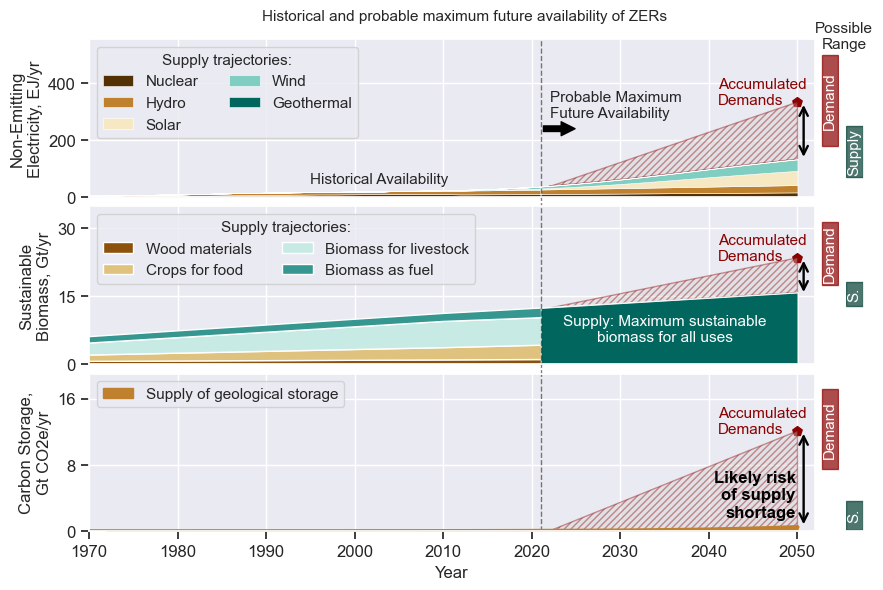

In [19]:
# Set up grid layout
fig = plt.figure(figsize=(10, 6))
gs = GridSpec(3, 3, 
              width_ratios= [0.75, 0.02, 0.02], 
              height_ratios = [1,1,1],
              hspace=0.06, wspace=0.02)

# Axis holders

ax_NEE = fig.add_subplot(gs[0, 0]) #ax_NEE
ax_Bio = fig.add_subplot(gs[1, 0], sharex=ax_NEE)#ax_Bio
ax_CS = fig.add_subplot(gs[2, 0], sharex=ax_NEE)#ax_CS

ax_NEE_demand = fig.add_subplot(gs[0, 1], sharey=ax_NEE)
ax_NEE_supply= fig.add_subplot(gs[0, 2], sharey=ax_NEE)
ax_Bio_demand = fig.add_subplot(gs[1, 1], sharey=ax_Bio)
ax_Bio_supply = fig.add_subplot(gs[1, 2], sharey=ax_Bio)
ax_CS_demand = fig.add_subplot(gs[2, 1], sharey=ax_CS)
ax_CS_supply = fig.add_subplot(gs[2, 2], sharey=ax_CS)

# organize  axes
axes = [
    [ax_NEE, ax_NEE_demand, ax_NEE_supply],
    [ax_Bio, ax_Bio_demand, ax_Bio_supply],
    [ax_CS, ax_CS_demand, ax_CS_supply]
]

#################################### ADJUST AXES #####################################

ax_NEE.set_xlim(1970, 2052) # Set the desired x-limits here

ax_NEE.set_ylim(0, max(ZER_Upper['NEE'], Demand_Upper['NEE'])*10/9)
ax_Bio.set_ylim(0, max(ZER_Upper['Bio'], Demand_Upper['Bio'])*10/9)
ax_CS.set_ylim(0, max(ZER_Upper['CS'], Demand_Upper['CS'])*10/9)

for ax in [ax_NEE, ax_Bio, ax_CS]:
    # This will try to create 5 major ticks and will remove the uppermost label if it's causing overlap.
    # You can adjust `nbins` to control the number of ticks.
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune='upper'))

AxisFontSize = 12
TextFontSize = 11
FontSize_Label = 11
RiskFontSize = 12

# Add an overall title to the graph
fig.suptitle('Historical and probable maximum future availability of ZERs', fontsize=FontSize_Label)
             # , fontweight='bold')


ax_Bio.set_ylabel('Sustainable\nBiomass, Gt/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_CS.set_ylabel('Carbon Storage,\nGt CO2e/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_NEE.set_ylabel('Non-Emitting\nElectricity, EJ/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_CS.set_xlabel('Year',  fontsize = AxisFontSize, fontweight = 'light')

ax_NEE.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=-1, ymax=1)
ax_Bio.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=-1, ymax=1)
ax_CS.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=0, ymax=1)

ax_NEE.text(Today+1, 289, 'Probable Maximum\nFuture Availability', fontsize = FontSize_Label, wrap=True)
arrow = mpatches.FancyArrowPatch((Today, 240), (Today+4.2, 240),
                                  mutation_scale=20, color='black')

# ax_NEE.text(Today+0.5, 98, 'Probable Maximum\nFuture Availability', fontsize = 11, wrap=True)
# arrow = mpatches.FancyArrowPatch((Today, 80), (Today+5.1, 80),
#                                   mutation_scale=20, color='black')

ax_NEE.add_patch(arrow)
ax_NEE.text(1995, 48, 'Historical Availability', fontsize = TextFontSize, wrap=True)

ax_Bio.text(2035, 5, 'Supply: Maximum sustainable\nbiomass for all uses', 
         horizontalalignment='center',
         fontsize = FontSize_Label,
         color = 'white')

######################## PLOT MODEL RESULTS ###################################

ax_NEE.scatter(2050, NEE_Model, marker=(5,0), s=50,  color = 'darkred', clip_on = False)
ax_Bio.scatter(2050, Bio_Model, marker=(5,0), s=50,  color = 'darkred')
ax_CS.scatter(2050, CS_Model, marker=(5,0), s=50,  color = 'darkred')


ax_NEE.text(2041, NEE_Model, 'Accumulated\nDemands', fontsize = FontSize_Label, wrap=True,  color = 'darkred')
ax_Bio.text(2041, Bio_Model, 'Accumulated\nDemands', fontsize = FontSize_Label, wrap=True,  color = 'darkred')
ax_CS.text(2041, CS_Model, 'Accumulated\nDemands', fontsize = FontSize_Label, wrap=True,  color = 'darkred')

# ax_NEE.annotate(s='', xy=(2050,100 ), xytext=(2050, NEE_Model), arrowprops=dict(arrowstyle='<->'))
ShortageDate = 2050.7

################################# DRAW RISK TRAJECTORIES ##########################

NEE_Today = Electricity_Generation.loc[2021].sum(axis = 0)
Bio_Today = Biomass_extraction.loc[2020].sum(axis = 0)
CS_Today = HaszeldineCurve[HaszeldineCurve.Year ==2021].HCurve

RiskTrajElec_lower = Electricity_Generation.loc[2022:2050].sum(axis = 1)
RiskTrajElec_upper = np.linspace(NEE_Today, NEE_Model, len(RiskTrajElec_lower))

RiskTrajBio_lower = Biomass_extraction.loc[2020:2050].sum(axis = 1)
RiskTrajBio_upper = np.linspace(Bio_Today, Bio_Model, len(RiskTrajBio_lower))

RiskTrajCS_lower  = HaszeldineCurve.set_index('Year', inplace = False).loc[2021:2050].squeeze()
RiskTrajCS_upper = np.linspace(CS_Today, CS_Model, len(RiskTrajCS_lower)).squeeze()


ax_NEE.fill_between(np.linspace(2022, 2050, len(RiskTrajElec_lower) ),
                  RiskTrajElec_lower, 
                  RiskTrajElec_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

ax_Bio.fill_between(np.linspace(2022, 2050, len(RiskTrajBio_lower) ),
                  RiskTrajBio_lower, 
                  RiskTrajBio_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

ax_CS.fill_between(np.linspace(2022, 2050, len(RiskTrajCS_lower) ),
                  RiskTrajCS_lower, 
                  RiskTrajCS_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

################################# DRAW RISK SPANS ~~~'###################################
ElecRisk = mpatches.FancyArrowPatch((ShortageDate, 131), (ShortageDate, NEE_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_NEE.add_patch(ElecRisk)



# ax_NEE.text(ShortageDate+1, NEE_Model/6*3, 'Likely risk of\nsupply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold', wrap=True,  color = 'black', ha = 'left')
# ax_Bio.text(ShortageDate+1, Bio_Model*5/8, 'Risk of\nsupply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold', wrap=True,  color = 'black', ha = 'left')
ax_CS.text(ShortageDate-0.9, CS_Model/6, 'Likely risk\nof supply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold',  wrap=True,  color = 'black', ha = 'right')

BioRisk = mpatches.FancyArrowPatch((ShortageDate,15.3), (ShortageDate, Bio_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_Bio.add_patch(BioRisk)

CSRisk = mpatches.FancyArrowPatch((ShortageDate,0.5), (ShortageDate, CS_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_CS.add_patch(CSRisk)


######################### PLOT TRAJECTORIES FROM DATA ####################################################

ax_NEE.stackplot(pd.array(Electricity_Generation.index), Electricity_Generation.T,

              labels  = pd.array(['Nuclear', 'Hydro', 'Solar', 'Wind', 'Geothermal', '_nolegend_', '_nolegend_', '_nolegend_', '_nolegend_', '_nolegend_']),
               # colors = sns.color_palette("hls", 5))
               colors = palette_elec,
              # colors = ['#a6cee3','#b2df8a','#fb9a99','#e31a1c','#cab2d6'])
               lw=0.4, edgecolor='white')



ax_Bio.stackplot(pd.array(Biomass_extraction.index), Biomass_extraction.T,
              labels  = pd.array(Biomass_extraction.columns), 
              # colors = ['#1f78b4','#33a02c','#fdbf6f','#6a3d9a'])
              # colors = sns.color_palette("hls", 4))
              colors = palette_bio)
                         

FutureBio =  Biomass_extraction.sum(1).loc[2020:2050]
FutureBioTime = np.linspace(2021, 2050, 4)

ax_Bio.fill_between(FutureBioTime, 
                FutureBio,
                color = '#01665e',
                edgecolor = 'white', lw = 0.6)

ax_CS.plot(HaszeldineCurve['Year'], HaszeldineCurve['HCurve'], 
         # linestyle = ':', 
         lw = 3,
         color = '#bf812d')


CCSProbableUpper = HaszeldineCurve.set_index('Year', inplace = False).loc[2021:2050].squeeze()



ax_CS.stackplot(pd.array(CarbonCapture_Cumulative.index), 
              CarbonCapture_Cumulative['Cumulative CCS Capacity']/1000, 
              CarbonCapture_Cumulative['Cumulative EOR Capacity']/1000,              
              labels  = ['Supply of geological storage'],
                          # 'In Construction', 
                          # 'In Development', 'In Early Development'], 
                              # lw=2, 
                              edgecolor='#bf812d',
                              # colors = ['#ff7f00','#b2df8a'])
                              # colors = sns.color_palette("hls", 2))
                              colors = palette_cs)

ax_CS.fill_between(np.linspace(Today, 2050, len(CCSProbableUpper) ),
                  np.zeros(len(CCSProbableUpper) ), 
                  CCSProbableUpper, 
                  color='#bf812d', 
                  # alpha=0.4, 
                  edgecolor = '#bf812d')
                   # label = 'Exponential capacity growth consistent with future\nplans considered against trends of past performance')

    
ax_NEE.legend(loc='upper left', title = 'Supply trajectories:', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 2)
ax_Bio.legend(loc='upper left', title = 'Supply trajectories:', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 2)
# , fontsize = TextFontSize)
ax_CS.legend(loc='upper left', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 2)

fig.tight_layout()
fig.subplots_adjust(top=0.93)

bar_width = 0.85

ax_NEE_demand.bar(x=[0], height = Demand_Upper['NEE']-Demand_Lower['NEE'], bottom=Demand_Lower['NEE'],
                  width=bar_width,
                  color=demand_colour, 
                  alpha = demand_alpha,
                  edgecolor=demand_colour)
ax_NEE_demand.text(0, (Demand_Upper['NEE'] + Demand_Lower['NEE'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_CS_demand.bar(x=[0], height = Demand_Upper['CS']-Demand_Lower['CS'], bottom=Demand_Lower['CS'],
                 width=bar_width,
                 color=demand_colour, 
                 alpha = demand_alpha,
                 edgecolor=demand_colour)
ax_CS_demand.text(0, (Demand_Upper['CS'] + Demand_Lower['CS'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)
ax_Bio_demand.bar(x=[0], height = Demand_Upper['Bio']-Demand_Lower['Bio'], bottom=Demand_Lower['Bio'],
                  width=bar_width,
                  color=demand_colour, 
                  alpha = demand_alpha,
                  edgecolor=demand_colour)
ax_Bio_demand.text(0, (Demand_Upper['Bio'] + Demand_Lower['Bio'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_NEE_supply.bar(x=[0], height = ZER_Upper['NEE']-ZER_Lower['NEE'], bottom=ZER_Lower['NEE'],
                  width=bar_width,
                  color=supply_colour, 
                  alpha = supply_alpha,
                  edgecolor=supply_colour)
ax_NEE_supply.text(0, (ZER_Upper['NEE'] + ZER_Lower['NEE'])/2,
                  'Supply',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

# Plot to ax_CS_supply
ax_CS_supply.bar(
    x=[0],
    height=[ZER_Upper['CS'] - ZER_Lower['CS']],
    bottom=[ZER_Lower['CS']],
    width=bar_width,
    color=supply_colour, 
    alpha = supply_alpha,
    edgecolor=supply_colour)
ax_CS_supply.text(0, (ZER_Upper['CS'] + ZER_Lower['CS'])/2,
                  'S.',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_Bio_supply.bar(x=[0], height = ZER_Upper['Bio']-ZER_Lower['Bio'], bottom=ZER_Lower['Bio'],
                  width=bar_width,
                  color=supply_colour, 
                  alpha = supply_alpha,
                  edgecolor=supply_colour)
ax_Bio_supply.text(0, (ZER_Upper['Bio'] + ZER_Lower['Bio'])/2,
                  'S.',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)


# Remove y-axis labels and ticks for demand/supply columns
for r in range(3):
    for c in range(1,3): # Columns 1 and 2 (demand and supply)
        axes[r][c].set_xlim(-0.5, 0.5) # A small range centered around 0 to show the bar at x=0
        plt.setp(axes[r][c].get_yticklabels(), visible=False)
        plt.setp(axes[r][c].get_ylabel(), visible=False)
        axes[r][c].tick_params(axis='y', length=0) # Remove tick marks
        axes[r][c].grid(False) # This turns off both x and y grids
        axes[r][c].set_facecolor('white') # Set to white
        plt.setp(axes[r][c].get_xticklabels(), visible=False)
        axes[r][c].tick_params(axis='x', length=0) # Remove tick marks

        # Remove x-axis labels and ticks for demand/supply columns
for r in range(2): # Rows 1 and 2
    for c in range(0,3): # Columns 1 and 2 (demand and supply)
        plt.setp(axes[r][c].get_xticklabels(), visible=False)
        axes[r][c].tick_params(axis='x', length=0) # Remove tick marks

#ax_CS_demand.set_xticks([0])
#ax_CS_demand.set_xticklabels(['Demand'], rotation=45, ha='right', fontsize = FontSize_Label)
#ax_CS_supply.set_xticks([0])
#ax_CS_supply.set_xticklabels(['Supply'], rotation=45, ha='right', fontsize = FontSize_Label)
fig.text(0.88, 0.91, 'Possible\nRange', ha='center', va='bottom', fontsize = FontSize_Label)


rcParams['pdf.fonttype'] = 42  # Export text as text, not paths

# plt.tight_layout()
plt.savefig("../Output/Figure2-Timeline.png", 
                            dpi = 600, bbox_inches = 'tight', facecolor='white', transparent=False)

plt.savefig("../Output/Figure2-Timeline.pdf", format="pdf", bbox_inches="tight")


plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_4240\2902513753.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


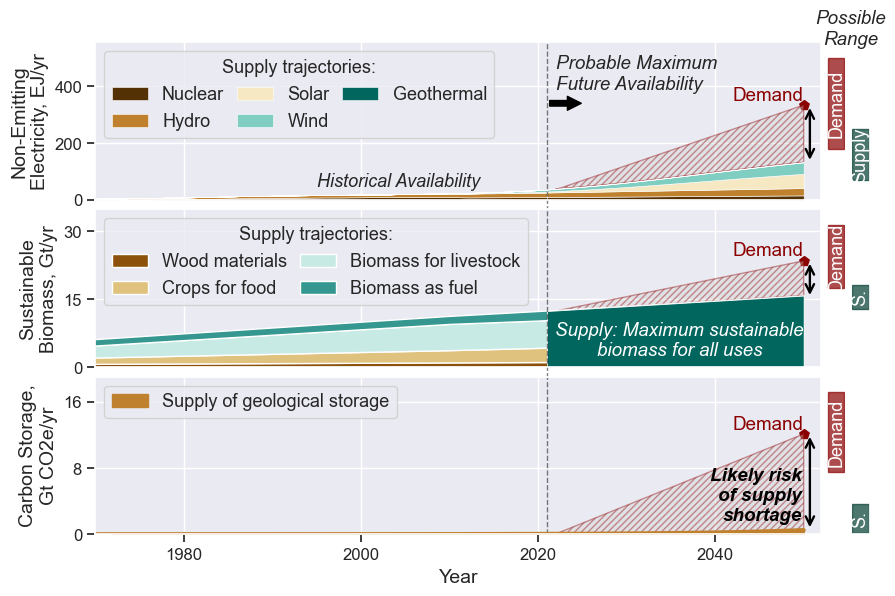

In [21]:
###### version of the plot for the poster (larger fonts)

# Set up grid layout
fig = plt.figure(figsize=(10, 6))
gs = GridSpec(3, 3, 
              width_ratios= [0.75, 0.02, 0.02], 
              height_ratios = [1,1,1],
              hspace=0.06, wspace=0.02)

# Axis holders

ax_NEE = fig.add_subplot(gs[0, 0]) #ax_NEE
ax_Bio = fig.add_subplot(gs[1, 0], sharex=ax_NEE)#ax_Bio
ax_CS = fig.add_subplot(gs[2, 0], sharex=ax_NEE)#ax_CS

ax_NEE_demand = fig.add_subplot(gs[0, 1], sharey=ax_NEE)
ax_NEE_supply= fig.add_subplot(gs[0, 2], sharey=ax_NEE)
ax_Bio_demand = fig.add_subplot(gs[1, 1], sharey=ax_Bio)
ax_Bio_supply = fig.add_subplot(gs[1, 2], sharey=ax_Bio)
ax_CS_demand = fig.add_subplot(gs[2, 1], sharey=ax_CS)
ax_CS_supply = fig.add_subplot(gs[2, 2], sharey=ax_CS)

# organize  axes
axes = [
    [ax_NEE, ax_NEE_demand, ax_NEE_supply],
    [ax_Bio, ax_Bio_demand, ax_Bio_supply],
    [ax_CS, ax_CS_demand, ax_CS_supply]
]

#################################### ADJUST AXES #####################################

ax_NEE.set_xlim(1970, 2052) # Set the desired x-limits here

ax_NEE.set_ylim(0, max(ZER_Upper['NEE'], Demand_Upper['NEE'])*10/9)
ax_Bio.set_ylim(0, max(ZER_Upper['Bio'], Demand_Upper['Bio'])*10/9)
ax_CS.set_ylim(0, max(ZER_Upper['CS'], Demand_Upper['CS'])*10/9)

for ax in [ax_NEE, ax_Bio, ax_CS]:
    # This will try to create 5 major ticks and will remove the uppermost label if it's causing overlap.
    # You can adjust `nbins` to control the number of ticks.
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune='upper'))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))

AxisFontSize = 14
TextFontSize = 13
FontSize_Label = 13.5
RiskFontSize = 13.5

# Add an overall title to the graph
#fig.suptitle('Historical and probable maximum future availability of ZERs', fontsize=FontSize_Label)
             # , fontweight='bold')


ax_Bio.set_ylabel('Sustainable\nBiomass, Gt/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_CS.set_ylabel('Carbon Storage,\nGt CO2e/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_NEE.set_ylabel('Non-Emitting\nElectricity, EJ/yr', fontsize = AxisFontSize, fontweight = 'light')
ax_CS.set_xlabel('Year',  fontsize = AxisFontSize, fontweight = 'light')

ax_NEE.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=-1, ymax=1)
ax_Bio.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=-1, ymax=1)
ax_CS.axvline(Today, color='black', ls='--', lw=1, alpha=0.5, clip_on = False, ymin=0, ymax=1)

ax_NEE.text(Today+1, 399, 'Probable Maximum\nFuture Availability', fontsize = FontSize_Label, wrap=True, style = 'italic')
arrow = mpatches.FancyArrowPatch((Today, 340), (Today+4.2, 340),
                                  mutation_scale=20, color='black')

# ax_NEE.text(Today+0.5, 98, 'Probable Maximum\nFuture Availability', fontsize = 11, wrap=True)
# arrow = mpatches.FancyArrowPatch((Today, 80), (Today+5.1, 80),
#                                   mutation_scale=20, color='black')

ax_NEE.add_patch(arrow)
ax_NEE.text(1995, 48, 'Historical Availability', fontsize = TextFontSize, wrap=True, style = 'italic')

ax_Bio.text(2036, 2.5, 'Supply: Maximum sustainable\nbiomass for all uses', 
         horizontalalignment='center',
         fontsize = FontSize_Label,
         color = 'white',
            style = 'italic')

######################## PLOT MODEL RESULTS ###################################

ax_NEE.scatter(2050, NEE_Model, marker=(5,0), s=50,  color = 'darkred', clip_on = False)
ax_Bio.scatter(2050, Bio_Model, marker=(5,0), s=50,  color = 'darkred')
ax_CS.scatter(2050, CS_Model, marker=(5,0), s=50,  color = 'darkred')


ax_NEE.text(2042, NEE_Model*1.05, 'Demand', fontsize = FontSize_Label, wrap=True,  color = 'darkred')
ax_Bio.text(2042, Bio_Model*1.05, 'Demand', fontsize = FontSize_Label, wrap=True,  color = 'darkred')
ax_CS.text(2042, CS_Model*1.05, 'Demand', fontsize = FontSize_Label, wrap=True,  color = 'darkred')

# ax_NEE.annotate(s='', xy=(2050,100 ), xytext=(2050, NEE_Model), arrowprops=dict(arrowstyle='<->'))
ShortageDate = 2050.7

################################# DRAW RISK TRAJECTORIES ##########################

NEE_Today = Electricity_Generation.loc[2021].sum(axis = 0)
Bio_Today = Biomass_extraction.loc[2020].sum(axis = 0)
CS_Today = HaszeldineCurve[HaszeldineCurve.Year ==2021].HCurve

RiskTrajElec_lower = Electricity_Generation.loc[2022:2050].sum(axis = 1)
RiskTrajElec_upper = np.linspace(NEE_Today, NEE_Model, len(RiskTrajElec_lower))

RiskTrajBio_lower = Biomass_extraction.loc[2020:2050].sum(axis = 1)
RiskTrajBio_upper = np.linspace(Bio_Today, Bio_Model, len(RiskTrajBio_lower))

RiskTrajCS_lower  = HaszeldineCurve.set_index('Year', inplace = False).loc[2021:2050].squeeze()
RiskTrajCS_upper = np.linspace(CS_Today, CS_Model, len(RiskTrajCS_lower)).squeeze()


ax_NEE.fill_between(np.linspace(2022, 2050, len(RiskTrajElec_lower) ),
                  RiskTrajElec_lower, 
                  RiskTrajElec_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

ax_Bio.fill_between(np.linspace(2022, 2050, len(RiskTrajBio_lower) ),
                  RiskTrajBio_lower, 
                  RiskTrajBio_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

ax_CS.fill_between(np.linspace(2022, 2050, len(RiskTrajCS_lower) ),
                  RiskTrajCS_lower, 
                  RiskTrajCS_upper, 
                  color='lightgray', 
                  alpha=0.4, 
                  edgecolor = 'darkred',
                  hatch = '/////')

################################# DRAW RISK SPANS ~~~'###################################
ElecRisk = mpatches.FancyArrowPatch((ShortageDate, 131), (ShortageDate, NEE_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_NEE.add_patch(ElecRisk)



# ax_NEE.text(ShortageDate+1, NEE_Model/6*3, 'Likely risk of\nsupply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold', wrap=True,  color = 'black', ha = 'left')
# ax_Bio.text(ShortageDate+1, Bio_Model*5/8, 'Risk of\nsupply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold', wrap=True,  color = 'black', ha = 'left')
ax_CS.text(ShortageDate-0.9, CS_Model/6, 'Likely risk\nof supply\nshortage', fontsize = RiskFontSize, fontweight  = 'bold',  style = 'italic', wrap=True,  color = 'black', ha = 'right')

BioRisk = mpatches.FancyArrowPatch((ShortageDate,15.3), (ShortageDate, Bio_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_Bio.add_patch(BioRisk)

CSRisk = mpatches.FancyArrowPatch((ShortageDate,0.5), (ShortageDate, CS_Model), arrowstyle='<->', mutation_scale=15, lw =1.7, color = 'black')
ax_CS.add_patch(CSRisk)


######################### PLOT TRAJECTORIES FROM DATA ####################################################

ax_NEE.stackplot(pd.array(Electricity_Generation.index), Electricity_Generation.T,

              labels  = pd.array(['Nuclear', 'Hydro', 'Solar', 'Wind', 'Geothermal', '_nolegend_', '_nolegend_', '_nolegend_', '_nolegend_', '_nolegend_']),
               # colors = sns.color_palette("hls", 5))
               colors = palette_elec,
              # colors = ['#a6cee3','#b2df8a','#fb9a99','#e31a1c','#cab2d6'])
               lw=0.4, edgecolor='white')



ax_Bio.stackplot(pd.array(Biomass_extraction.index), Biomass_extraction.T,
              labels  = pd.array(Biomass_extraction.columns), 
              # colors = ['#1f78b4','#33a02c','#fdbf6f','#6a3d9a'])
              # colors = sns.color_palette("hls", 4))
              colors = palette_bio)
                         

FutureBio =  Biomass_extraction.sum(1).loc[2020:2050]
FutureBioTime = np.linspace(2021, 2050, 4)

ax_Bio.fill_between(FutureBioTime, 
                FutureBio,
                color = '#01665e',
                edgecolor = 'white', lw = 0.6)

ax_CS.plot(HaszeldineCurve['Year'], HaszeldineCurve['HCurve'], 
         # linestyle = ':', 
         lw = 3,
         color = '#bf812d')


CCSProbableUpper = HaszeldineCurve.set_index('Year', inplace = False).loc[2021:2050].squeeze()



ax_CS.stackplot(pd.array(CarbonCapture_Cumulative.index), 
              CarbonCapture_Cumulative['Cumulative CCS Capacity']/1000, 
              CarbonCapture_Cumulative['Cumulative EOR Capacity']/1000,              
              labels  = ['Supply of geological storage'],
                          # 'In Construction', 
                          # 'In Development', 'In Early Development'], 
                              # lw=2, 
                              edgecolor='#bf812d',
                              # colors = ['#ff7f00','#b2df8a'])
                              # colors = sns.color_palette("hls", 2))
                              colors = palette_cs)

ax_CS.fill_between(np.linspace(Today, 2050, len(CCSProbableUpper) ),
                  np.zeros(len(CCSProbableUpper) ), 
                  CCSProbableUpper, 
                  color='#bf812d', 
                  # alpha=0.4, 
                  edgecolor = '#bf812d')
                   # label = 'Exponential capacity growth consistent with future\nplans considered against trends of past performance')

    
ax_NEE.legend(loc='upper left', title = 'Supply trajectories:', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 3, columnspacing = 0.7)
ax_Bio.legend(loc='upper left', title = 'Supply trajectories:', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 2, columnspacing = 0.7)
# , fontsize = TextFontSize)
ax_CS.legend(loc='upper left', fontsize = TextFontSize, title_fontsize = TextFontSize, ncol = 2)

fig.tight_layout()
fig.subplots_adjust(top=0.93)

bar_width = 0.85

ax_NEE_demand.bar(x=[0], height = Demand_Upper['NEE']-Demand_Lower['NEE'], bottom=Demand_Lower['NEE'],
                  width=bar_width,
                  color=demand_colour, 
                  alpha = demand_alpha,
                  edgecolor=demand_colour)
ax_NEE_demand.text(0, (Demand_Upper['NEE'] + Demand_Lower['NEE'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_CS_demand.bar(x=[0], height = Demand_Upper['CS']-Demand_Lower['CS'], bottom=Demand_Lower['CS'],
                 width=bar_width,
                 color=demand_colour, 
                 alpha = demand_alpha,
                 edgecolor=demand_colour)
ax_CS_demand.text(0, (Demand_Upper['CS'] + Demand_Lower['CS'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)
ax_Bio_demand.bar(x=[0], height = Demand_Upper['Bio']-Demand_Lower['Bio'], bottom=Demand_Lower['Bio'],
                  width=bar_width,
                  color=demand_colour, 
                  alpha = demand_alpha,
                  edgecolor=demand_colour)
ax_Bio_demand.text(0, (Demand_Upper['Bio'] + Demand_Lower['Bio'])/2,
                  'Demand',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_NEE_supply.bar(x=[0], height = ZER_Upper['NEE']-ZER_Lower['NEE'], bottom=ZER_Lower['NEE'],
                  width=bar_width,
                  color=supply_colour, 
                  alpha = supply_alpha,
                  edgecolor=supply_colour)
ax_NEE_supply.text(0, (ZER_Upper['NEE'] + ZER_Lower['NEE'])/2,
                  'Supply',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

# Plot to ax_CS_supply
ax_CS_supply.bar(
    x=[0],
    height=[ZER_Upper['CS'] - ZER_Lower['CS']],
    bottom=[ZER_Lower['CS']],
    width=bar_width,
    color=supply_colour, 
    alpha = supply_alpha,
    edgecolor=supply_colour)
ax_CS_supply.text(0, (ZER_Upper['CS'] + ZER_Lower['CS'])/2,
                  'S.',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)

ax_Bio_supply.bar(x=[0], height = ZER_Upper['Bio']-ZER_Lower['Bio'], bottom=ZER_Lower['Bio'],
                  width=bar_width,
                  color=supply_colour, 
                  alpha = supply_alpha,
                  edgecolor=supply_colour)
ax_Bio_supply.text(0, (ZER_Upper['Bio'] + ZER_Lower['Bio'])/2,
                  'S.',
                   rotation = 90,
                  ha='center', va='center', color='white', fontsize=TextFontSize)


# Remove y-axis labels and ticks for demand/supply columns
for r in range(3):
    for c in range(1,3): # Columns 1 and 2 (demand and supply)
        axes[r][c].set_xlim(-0.5, 0.5) # A small range centered around 0 to show the bar at x=0
        plt.setp(axes[r][c].get_yticklabels(), visible=False)
        plt.setp(axes[r][c].get_ylabel(), visible=False)
        axes[r][c].tick_params(axis='y', length=0) # Remove tick marks
        axes[r][c].grid(False) # This turns off both x and y grids
        axes[r][c].set_facecolor('white') # Set to white
        plt.setp(axes[r][c].get_xticklabels(), visible=False)
        axes[r][c].tick_params(axis='x', length=0) # Remove tick marks

        # Remove x-axis labels and ticks for demand/supply columns
for r in range(2): # Rows 1 and 2
    for c in range(0,3): # Columns 1 and 2 (demand and supply)
        plt.setp(axes[r][c].get_xticklabels(), visible=False)
        axes[r][c].tick_params(axis='x', length=0) # Remove tick marks

#ax_CS_demand.set_xticks([0])
#ax_CS_demand.set_xticklabels(['Demand'], rotation=45, ha='right', fontsize = FontSize_Label)
#ax_CS_supply.set_xticks([0])
#ax_CS_supply.set_xticklabels(['Supply'], rotation=45, ha='right', fontsize = FontSize_Label)
fig.text(0.88, 0.92, 'Possible\nRange', ha='center', va='bottom', fontsize = FontSize_Label, style = 'italic')


plt.show()